# Gaussian Naive Bayes and the GMM comparison

PISA 2022, six education systems. Mohamed's R3 task is to classify whether a student is below mathematics Level 2, using `GaussianNB`, and compare it with the Gaussian mixture in `02_data-analysis/03_clustering.ipynb`.

This notebook follows the shared data-loading structure in Fathah's decision-tree notebook, then adds the complete classification experiment. GaussianNB is a classifier, so this task has no maths-score regression model. Class **1** means below Level 2, using the existing targets and their **420.07** cutoff.

We hold out the same five school folds, train Naive Bayes with SENWT, retain missing indicators, and evaluate all ten plausible values. No hyperparameters or decision thresholds are selected using these evaluation folds. Defaults are fixed before running.

**Provenance and AI use:** prepared with OpenAI Codex assistance for Mohamed to review and adapt. Clean data and folds come from `Ahmed-EDA` (`d9ad35d`); notebook structure was inspected on `Fathah-Models` (`dec8c4a`). The GMM comparison is a new evaluation of the method, not reuse of a model fitted on all students.

## 1. Imports and shared data

In [1]:
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    recall_score, brier_score_loss, confusion_matrix, roc_curve,
)
from threadpoolctl import threadpool_limits

# Support launching Jupyter from the repository root or this notebook's folder.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/clean/columns.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the PISA repository with data/clean available.")
DATA = ROOT / "data/clean"
OUT = ROOT / "03_baselines/outputs/mohamed_naive_bayes"
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(DATA / "pisa6_clean.parquet")
roles = json.loads((DATA / "columns.json").read_text(encoding="utf-8"))
folds = pd.read_csv(DATA / "folds.csv")

# Join by both system and school, so school IDs never mix across systems.
keys = ["CNT", "CNTSCHID"]
assert not df.duplicated(keys + ["CNTSTUID"]).any()
assert not folds.duplicated(keys).any()
df = df.merge(folds[keys + ["fold"]], on=keys, how="left", validate="many_to_one")
assert df["fold"].notna().all(), "Every student must have a shared school fold."
assert set(df["fold"]) == set(range(5))
assert df.groupby(keys)["fold"].nunique().eq(1).all()
df["fold"] = df["fold"].astype(int)
print(f"Students: {len(df):,}; schools: {len(folds):,}; systems: {df.CNT.nunique()}")
print(f"Python {platform.python_version()}; scikit-learn {sklearn.__version__}")
display(df.groupby("fold").agg(students=("CNTSTUID", "size"), schools=("CNTSCHID", "nunique")))

Students: 61,775; schools: 1,973; systems: 6
Python 3.12.14; scikit-learn 1.9.1


,students,schools
fold,,
0,12340,397
1,12330,396
2,12365,394
3,12361,394
4,12379,392


## 2. Features and model assumptions

The EDA found that ESCS is an exact combination of PAREDINT, HISEI and HOMEPOS. Following the agreed Naive Bayes specification, we keep ESCS and remove those three components **and their missing flags**. That leaves 14 predictors and 14 missing flags. IDs, country, weights, scores and quality flags are excluded from the feature matrix.

GaussianNB estimates a Gaussian distribution for each feature within each observed class, assumes features are conditionally independent, and applies Bayes' rule. It is a **supervised generative classifier**. Removing the ESCS duplication reduces dependence but does not make the remaining features independent. Binary indicators are also an approximation under a Gaussian model. Small class-specific variances can produce extreme probabilities, so we report Brier loss alongside discrimination and recall.

Training-fold median imputation and robust scaling follow `NEXT_STEPS.md`. Scaling is mainly useful for numerical consistency here. GaussianNB uses its fixed default `var_smoothing=1e-9` and learns class priors from the survey-weighted training labels. We use a fixed probability threshold of 0.5 without class rebalancing.

In [2]:
all_predictors = [c for cols in roles["feature_groups"].values() for c in cols]
drop = {"PAREDINT", "HISEI", "HOMEPOS"}
predictors = [c for c in all_predictors if c not in drop]
features = predictors + [f"{c}_missing" for c in predictors]
assert len(predictors) == 14 and len(features) == 28
assert len(features) == len(set(features)) and set(features).issubset(df.columns)
forbidden = set(roles["ids"] + roles["targets"]["classification"]
                + roles["targets"]["regression"])
assert not forbidden.intersection(features)
assert not any("PV" in c or "W_FST" in c for c in features)
assert np.isfinite(df["SENWT"]).all() and df["SENWT"].gt(0).all()

X = df[features]
targets = df[roles["targets"]["classification"]].to_numpy(dtype=int)
assert targets.shape == (len(df), 10) and set(np.unique(targets)) == {0, 1}
w = df["SENWT"].to_numpy(dtype=float)
fold_id = df["fold"].to_numpy()
print("Predictors:", predictors)
print("Weighted below-Level-2 share, averaged across PVs:",
      round(np.average(targets.mean(axis=1), weights=w), 4))
display(df.groupby("CNT")["SENWT"].sum().rename("senate_weight_sum"))

def metrics(y, p, weights):
    pred = p >= 0.5
    return {
        "roc_auc": roc_auc_score(y, p, sample_weight=weights),
        "pr_auc": average_precision_score(y, p, sample_weight=weights),
        "balanced_acc": balanced_accuracy_score(y, pred, sample_weight=weights),
        "recall_below_l2": recall_score(y, pred, pos_label=1, sample_weight=weights, zero_division=0),
        "recall_at_or_above_l2": recall_score(y, pred, pos_label=0, sample_weight=weights, zero_division=0),
        "brier_loss": brier_score_loss(y, p, sample_weight=weights),
    }

Predictors: ['ESCS', 'ANXMAT', 'MATHEFF', 'MATHEF21', 'DISCLIM', 'TEACHSUP', 'BELONG', 'BULLIED', 'EDUSHORT', 'STAFFSHORT', 'MCLSIZE', 'STRATIO', 'SCHL_PRIVATE', 'SCHSIZE_log']
Weighted below-Level-2 share, averaged across PVs: 0.6998


CNT
ARE    4999.99341
JOR    4999.99980
MAR    5000.00134
PSE    4999.99998
QAT    4999.99862
SAU    4999.99983
Name: senate_weight_sum, dtype: float64

## 3. Naive Bayes on all ten plausible values

For each held-out school fold, fit preprocessing using training students only. For each plausible value, fit a fresh weighted GaussianNB and predict only the held-out students. Each student receives exactly one out-of-fold probability per plausible value. The prior-only baseline predicts the training fold's weighted prevalence, giving context for the strong class imbalance.

ROC-AUC measures ranking, PR-AUC here means **average precision** for class 1, balanced accuracy averages the two recalls, and Brier loss measures squared probability error (lower is better). Final pooled scores use the full out-of-fold vector per plausible value, then average over plausible values. We do not average labels or probabilities across plausible values before scoring.

In [3]:
probabilities = {
    "GaussianNB": np.full(targets.shape, np.nan),
    "Prior baseline": np.full(targets.shape, np.nan),
}
fold_rows = []
coverage = np.zeros(len(df), dtype=int)
for k in range(5):
    train, test = fold_id != k, fold_id == k
    train_schools = set(map(tuple, df.loc[train, keys].to_numpy()))
    test_schools = set(map(tuple, df.loc[test, keys].to_numpy()))
    assert train_schools.isdisjoint(test_schools)
    prep = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), RobustScaler())
    xtrain = prep.fit_transform(X.loc[train])
    xtest = prep.transform(X.loc[test])
    assert np.isfinite(xtrain).all() and np.isfinite(xtest).all()
    train_w = w[train] / w[train].mean()
    for j in range(10):
        ytrain, ytest = targets[train, j], targets[test, j]
        model = GaussianNB(var_smoothing=1e-9)
        model.fit(xtrain, ytrain, sample_weight=train_w)
        positive_col = np.flatnonzero(model.classes_ == 1).item()
        p = model.predict_proba(xtest)[:, positive_col]
        probabilities["GaussianNB"][test, j] = p
        probabilities["Prior baseline"][test, j] = np.average(ytrain, weights=train_w)
        fold_rows.append({"model": "GaussianNB", "pv": j + 1, "fold": k,
                          **metrics(ytest, p, w[test])})
    coverage[test] += 1
    print(f"Naive Bayes: finished fold {k + 1}/5 (10 PVs)")
assert (coverage == 1).all()

Naive Bayes: finished fold 1/5 (10 PVs)


Naive Bayes: finished fold 2/5 (10 PVs)


Naive Bayes: finished fold 3/5 (10 PVs)


Naive Bayes: finished fold 4/5 (10 PVs)


Naive Bayes: finished fold 5/5 (10 PVs)


## 4. How this differs from the GMM in 03_clustering

Both models are generative. GaussianNB learns class-conditional distributions from known labels. The GMM learns latent groups without knowing the below-Level-2 labels. The original GMM used all 17 predictors, full covariance matrices, median fill, 1–99% clipping and standard scaling. PCA was used for visualisation, not as its fitted input. BIC continued to decrease across the tested component counts, so it did not establish a natural number of clusters. The cluster profiles in section 3.5 are **k-means** profiles and must not be described as GMM results.

For an illustrative predictive comparison, we refit a **two-component** GMM separately inside each training fold. Two components are fixed in advance for this binary-risk experiment; this is not a claim that BIC chose two. We retain the original 17-feature preprocessing and full covariance structure. Nothing fitted on the complete dataset in `03_clustering` is reused.

A component ID is not a class label. For each PV, we estimate each component's below-Level-2 rate using **training labels and SENWT**, weighted by the GMM's soft memberships. Held-out risk is the sum of membership probability times training component risk. This mapping handles arbitrary component numbering without seeing held-out labels.

**Comparison limits:** scikit-learn `GaussianMixture.fit` has no `sample_weight` argument, so EM fitting remains unweighted, matching `03_clustering`. Risk mapping and evaluation are weighted. Naive Bayes has 14 predictors plus missing flags, whereas this GMM uses the original 17 predictors without flags. These are the two agreed method specifications, not a controlled test of the algorithm alone. A matched-input sensitivity below also runs GaussianNB on the GMM's exact preprocessed 17 inputs. This controls the feature and preprocessing differences, while the EM weighting difference remains.

In [4]:
probabilities["GMM + training risk"] = np.full(targets.shape, np.nan)
probabilities["GaussianNB matched inputs"] = np.full(targets.shape, np.nan)
gmm_rows = []
for k in range(5):
    train, test = fold_id != k, fold_id == k
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    a = imputer.fit_transform(df.loc[train, all_predictors])
    b = imputer.transform(df.loc[test, all_predictors])
    lo, hi = np.quantile(a, [0.01, 0.99], axis=0)
    scaler = StandardScaler()
    a = scaler.fit_transform(np.clip(a, lo, hi))
    b = scaler.transform(np.clip(b, lo, hi))
    gmm = GaussianMixture(n_components=2, covariance_type="full", random_state=0,
                          n_init=1, max_iter=100, reg_covar=1e-6)
    # Limit BLAS threads to avoid oversubscription on laptops.
    with threadpool_limits(limits=2):
        gmm.fit(a)
        train_r = gmm.predict_proba(a)
        test_r = gmm.predict_proba(b)
    assert gmm.converged_, f"GMM did not converge for fold {k}"
    mass = (train_r * w[train, None]).sum(axis=0)
    assert (mass > 0).all()
    component_risk = (train_r.T @ (targets[train] * w[train, None])) / mass[:, None]
    p = test_r @ component_risk
    probabilities["GMM + training risk"][test] = p
    for j in range(10):
        matched = GaussianNB(var_smoothing=1e-9).fit(
            a, targets[train, j], sample_weight=w[train] / w[train].mean())
        probabilities["GaussianNB matched inputs"][test, j] = matched.predict_proba(b)[:, 1]
        fold_rows.append({"model": "GMM + training risk", "pv": j + 1, "fold": k,
                          **metrics(targets[test, j], p[:, j], w[test])})
    gmm_rows.append({"fold": k, "n_components": 2, "converged": gmm.converged_,
                     "iterations": gmm.n_iter_, "training_bic": gmm.bic(a),
                     "component_0_risk_mean_pv": component_risk[0].mean(),
                     "component_1_risk_mean_pv": component_risk[1].mean()})
    print(f"GMM and matched-input NB: finished fold {k + 1}/5")

for name, p in probabilities.items():
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all(), name
display(pd.DataFrame(gmm_rows).round(4))

GMM and matched-input NB: finished fold 1/5


GMM and matched-input NB: finished fold 2/5


GMM and matched-input NB: finished fold 3/5


GMM and matched-input NB: finished fold 4/5


GMM and matched-input NB: finished fold 5/5


,fold,n_components,converged,iterations,training_bic,component_0_risk_mean_pv,component_1_risk_mean_pv
0,0,2,True,10,1.329512e+06,0.7894,0.4393
1,1,2,True,13,1.327725e+06,0.7909,0.4388
2,2,2,True,9,1.323659e+06,0.7901,0.4144
3,3,2,True,12,1.325275e+06,0.7926,0.4361
4,4,2,True,29,1.630944e+06,0.6704,0.8315


## 5. Pooled and per-system results

We score SENWT-weighted pooled predictions and W_FSTUWT-weighted predictions within each system. All displayed scores are averages of ten separately evaluated PVs. The prior baseline is fitted separately by fold, so its pooled ROC-AUC can differ slightly from 0.5. Its threshold-based predictions are usually the majority class.

In [5]:
systems = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]
domains = {"Pooled": np.ones(len(df), dtype=bool)}
domains.update({s: df["CNT"].eq(s).to_numpy() for s in systems})
pv_rows = []
for domain, mask in domains.items():
    weights = w[mask] if domain == "Pooled" else df.loc[mask, "W_FSTUWT"].to_numpy()
    for name, p in probabilities.items():
        for j in range(10):
            pv_rows.append({"domain": domain, "model": name, "pv": j + 1,
                            **metrics(targets[mask, j], p[mask, j], weights)})
per_pv = pd.DataFrame(pv_rows)
metric_names = list(metrics(targets[:, 0], probabilities["GaussianNB"][:, 0], w))
scores = per_pv.groupby(["domain", "model"])[metric_names].mean()
display(scores.loc["Pooled"].round(4))
display(scores.xs("GaussianNB", level="model").reindex(["Pooled"] + systems).round(4))

,roc_auc,pr_auc,balanced_acc,recall_below_l2,recall_at_or_above_l2,brier_loss
model,,,,,,
GMM + training risk,0.6601,0.7845,0.6324,0.8640,0.4007,0.1900
GaussianNB,0.7532,0.8480,0.7001,0.7757,0.6246,0.2190
GaussianNB matched inputs,0.7728,0.8674,0.7061,0.7425,0.6698,0.2210
Prior baseline,0.4911,0.6955,0.5000,1.0000,0.0000,0.2101


,roc_auc,pr_auc,balanced_acc,recall_below_l2,recall_at_or_above_l2,brier_loss
domain,,,,,,
Pooled,0.7532,0.8480,0.7001,0.7757,0.6246,0.2190
ARE,0.7286,0.7124,0.6740,0.4774,0.8705,0.2780
SAU,0.6558,0.7951,0.6191,0.6659,0.5724,0.2741
QAT,0.7571,0.7568,0.6924,0.6441,0.7408,0.2537
JOR,0.7296,0.9139,0.6485,0.8656,0.4314,0.1663
MAR,0.7011,0.9087,0.5845,0.9126,0.2564,0.1849
PSE,0.7349,0.8962,0.6219,0.9149,0.3288,0.1568


## 6. Conditional uncertainty from replicate weights and plausible values

For the primary GaussianNB results, we recompute each metric with the 80 Fay BRR replicate weights. Within a PV, variance is `sum((replicate_score - full_score)**2) / (80 * (1 - 0.5)**2)`. Across the ten PVs we use `mean(within_variance) + (1 + 1/10) * variance(pv_scores)`. The pooled replicate weights are normalised separately within each system to the same senate total, retaining equal-system weighting.

**Scope of these margins:** the out-of-fold models, imputers, scalers and predictions stay fixed while evaluation weights change. These are **conditional evaluation standard errors**, including PV variation, rather than a complete variance estimate for the training procedure. Replicate refitting of the full pipeline would be needed to include training variation. They are not fold standard deviations, and overlap or separation of these margins alone is not a paired significance test. The team should preserve this qualification in the report.

In [6]:
replicate_cols = roles["weights"]["replicates"]
assert len(replicate_cols) == 80 and set(replicate_cols).issubset(df.columns)
replicates = df[replicate_cols].to_numpy(dtype=float)
assert np.isfinite(replicates).all() and (replicates >= 0).all()
pooled_replicates = replicates.copy()
for system in systems:
    mask = domains[system]
    pooled_replicates[mask] *= w[mask].sum() / replicates[mask].sum(axis=0)

uncertainty_rows = []
for domain, mask in domains.items():
    rweights = pooled_replicates[mask] if domain == "Pooled" else replicates[mask]
    full = per_pv[(per_pv.domain == domain) & (per_pv.model == "GaussianNB")].sort_values("pv")
    estimates = full[metric_names].to_numpy()
    within = []
    for j in range(10):
        y = targets[mask, j]
        p = probabilities["GaussianNB"][mask, j]
        rep_scores = np.array([list(metrics(y, p, rweights[:, r]).values()) for r in range(80)])
        within.append(((rep_scores - estimates[j]) ** 2).sum(axis=0) / (80 * 0.5**2))
    total_var = np.mean(within, axis=0) + 1.1 * estimates.var(axis=0, ddof=1)
    for metric, score, se in zip(metric_names, estimates.mean(axis=0), np.sqrt(total_var)):
        uncertainty_rows.append({"domain": domain, "model": "GaussianNB", "metric": metric,
                                 "score": score, "conditional_se": se})
    print(f"Conditional BRR + PV uncertainty: {domain}")
uncertainty = pd.DataFrame(uncertainty_rows)
display(uncertainty[uncertainty.domain == "Pooled"].round(4))

Conditional BRR + PV uncertainty: Pooled


Conditional BRR + PV uncertainty: ARE


Conditional BRR + PV uncertainty: SAU


Conditional BRR + PV uncertainty: QAT


Conditional BRR + PV uncertainty: JOR


Conditional BRR + PV uncertainty: MAR


Conditional BRR + PV uncertainty: PSE


,domain,model,metric,score,conditional_se
0,Pooled,GaussianNB,roc_auc,0.7532,0.0052
1,Pooled,GaussianNB,pr_auc,0.8480,0.0053
2,Pooled,GaussianNB,balanced_acc,0.7001,0.0043
3,Pooled,GaussianNB,recall_below_l2,0.7757,0.0088
4,Pooled,GaussianNB,recall_at_or_above_l2,0.6246,0.0118
5,Pooled,GaussianNB,brier_loss,0.2190,0.0041


## 7. Diagnostics across all plausible values

The ROC curves below are averages of the ten out-of-fold curves. Confusion matrices are computed separately by PV with SENWT and then averaged, so both the displayed rates and curves use all ten PVs. They do not turn the ten targets into a single consensus label.

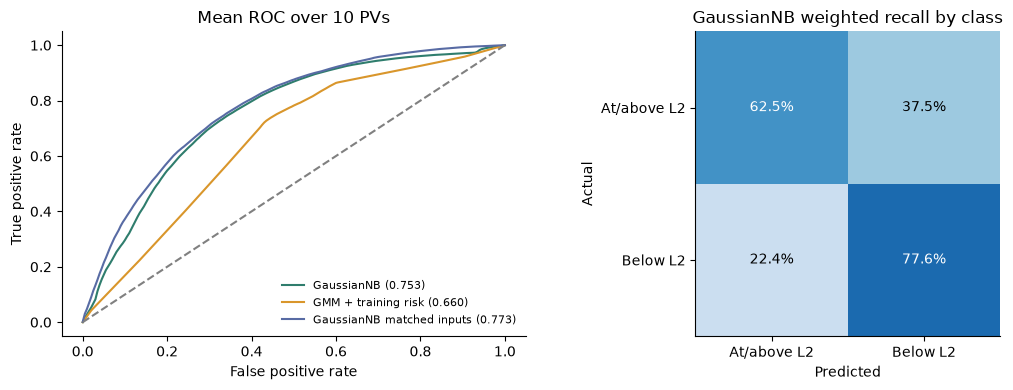

In [7]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
grid = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colours = {"GaussianNB": "#2F7D6D", "GMM + training risk": "#D9962B",
           "GaussianNB matched inputs": "#586BA4"}
for name, colour in colours.items():
    curves = []
    for j in range(10):
        fpr, tpr, _ = roc_curve(targets[:, j], probabilities[name][:, j], sample_weight=w)
        curves.append(np.interp(grid, fpr, tpr))
    auc = scores.loc[("Pooled", name), "roc_auc"]
    axes[0].plot(grid, np.mean(curves, axis=0), label=f"{name} ({auc:.3f})", color=colour)
axes[0].plot([0, 1], [0, 1], ls="--", color="grey")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="Mean ROC over 10 PVs")
axes[0].legend(frameon=False, fontsize=8)
cm = np.mean([confusion_matrix(targets[:, j], probabilities["GaussianNB"][:, j] >= 0.5,
                             labels=[0, 1], sample_weight=w, normalize="true")
              for j in range(10)], axis=0)
axes[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
for row in range(2):
    for col in range(2):
        axes[1].text(col, row, f"{cm[row, col]:.1%}", ha="center", va="center",
                     color="white" if cm[row, col] > 0.6 else "black")
axes[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["At/above L2", "Below L2"],
            yticklabels=["At/above L2", "Below L2"], xlabel="Predicted", ylabel="Actual",
            title="GaussianNB weighted recall by class")
fig.tight_layout()
fig.savefig(OUT / "roc_and_confusion.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Interpretation and saved results

The printed statements below describe this run. Higher ROC-AUC means better ranking; it does not establish that probability estimates are calibrated or that the difference is statistically significant. The GMM comparison evaluates how well unsupervised groups support class-risk prediction after a training-only risk mapping. It does not compare silhouette or BIC numerically against ROC-AUC, because those scores answer different questions.

If GaussianNB has high below-Level-2 recall but low recall for the other class, the 0.5 threshold is favouring the majority class. Missing flags and remaining correlated features can make its probabilities overconfident. The matched-input result helps assess whether feature choices explain part of the NB–GMM gap. Country is excluded as a predictor, although other features can still encode system differences. These results describe generalisation to held-out schools in these six systems, not transfer to a new country or causal effects of a factor.

CSV outputs give Ahmed pooled and per-system results, per-PV and fold diagnostics, and the primary model's explicitly conditional standard errors. An out-of-fold Parquet file retains student IDs, weights, targets and all predictions for paired comparisons and later evaluation. No model is trained on all students for deployment in this notebook.

In [8]:
main = scores.loc[("Pooled", "GaussianNB")]
comparison = scores.loc[("Pooled", "GMM + training risk")]
print(f"GaussianNB: ROC-AUC {main.roc_auc:.3f}, average precision {main.pr_auc:.3f}, "
      f"balanced accuracy {main.balanced_acc:.3f}.")
print(f"Recall below L2: {main.recall_below_l2:.3f}; "
      f"recall at/above L2: {main.recall_at_or_above_l2:.3f}; Brier loss: {main.brier_loss:.3f}.")
print(f"GMM + training risk ROC-AUC: {comparison.roc_auc:.3f}; "
      f"NB minus GMM: {main.roc_auc - comparison.roc_auc:+.3f} (descriptive difference).")

pd.DataFrame(fold_rows).to_csv(OUT / "fold_metrics.csv", index=False)
per_pv.to_csv(OUT / "per_pv_metrics.csv", index=False)
scores.reset_index().to_csv(OUT / "summary_metrics.csv", index=False)
uncertainty.to_csv(OUT / "naive_bayes_conditional_se.csv", index=False)
pd.DataFrame(gmm_rows).to_csv(OUT / "gmm_diagnostics.csv", index=False)
oof = df[keys + ["CNTSTUID", "fold", "SENWT", "W_FSTUWT"]
         + roles["targets"]["classification"]].copy()
prefixes = {"GaussianNB": "nb", "Prior baseline": "prior",
            "GMM + training risk": "gmm", "GaussianNB matched inputs": "nb_matched"}
for name, p in probabilities.items():
    for j in range(10):
        oof[f"{prefixes[name]}_p_pv{j + 1}"] = p[:, j]
oof.to_parquet(OUT / "out_of_fold_predictions.parquet", index=False)
manifest = {
    "python": platform.python_version(), "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__,
    "students": len(df), "schools": len(folds), "features": features,
    "naive_bayes_var_smoothing": 1e-9, "threshold": 0.5,
    "gmm_components": 2, "gmm_random_state": 0, "gmm_em_weighted": False,
    "uncertainty": "Fay BRR + Rubin PV pooling, conditional on fixed OOF predictions",
    "input_sha256": {name: hashlib.sha256((DATA / name).read_bytes()).hexdigest()
                     for name in ["pisa6_clean.parquet", "columns.json", "folds.csv"]},
}
(OUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved results to", OUT.relative_to(ROOT))

GaussianNB: ROC-AUC 0.753, average precision 0.848, balanced accuracy 0.700.
Recall below L2: 0.776; recall at/above L2: 0.625; Brier loss: 0.219.
GMM + training risk ROC-AUC: 0.660; NB minus GMM: +0.093 (descriptive difference).


Saved results to 03_baselines\outputs\mohamed_naive_bayes


### Findings from the verified run

On the frozen 61,775-student table, the primary GaussianNB reached **ROC-AUC 0.753**, **average precision 0.848**, and **balanced accuracy 0.700**. Its recall was **0.776 below Level 2** and **0.625 at or above Level 2**. The conditional evaluation SE for ROC-AUC was **0.005**; this does not include full training-procedure uncertainty.

The two-component GMM plus training-only risk mapping reached **ROC-AUC 0.660**. GaussianNB using the GMM's exact inputs and preprocessing reached **0.773**, so the ranking advantage remained under the matched-input check. EM weighting still differs, and the comparison covers only this fixed two-component GMM. It does not show that Naive Bayes outperforms every possible GMM specification.

Probability quality tells a different story: GaussianNB's **Brier loss was 0.219**, compared with **0.210 for the prior-only baseline** and **0.190 for the GMM risk model**. Lower is better. GaussianNB ranks students better here but its raw probabilities have worse squared error, consistent with the concern about overconfidence. Probability calibration and smoothing are possible follow-up experiments and would need validation inside training schools before evaluation.

These numbers describe the saved run and its input hashes in `run_manifest.json`. If inputs or model settings change, rerun the code and revise this interpretation before reporting it.


## Sources and review notes

- Local specification: `NEXT_STEPS.md`, `data/clean/columns.json`, and the four `Ahmed-EDA` notebooks. The supplied findings documents were read as context; this notebook's actions follow Mohamed's request.
- Structure reference: `Fathah-Models/03_baselines/fathah_decision_tree.ipynb`, inspected at `dec8c4a`. At that commit it contains imports, a data-loading cell with a saved path error, and an unfinished feature comprehension; it is not a completed modelling baseline.
- [scikit-learn GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html): weighted fitting, variance smoothing and learned priors.
- [scikit-learn Naive Bayes guide](https://scikit-learn.org/stable/modules/naive_bayes.html): conditional independence, Gaussian likelihoods and probability limitations.
- [scikit-learn GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html): EM, full covariance, BIC, soft memberships and the unweighted fit interface.
- [OECD PISA Data Analysis Manual](https://www.oecd.org/en/publications/pisa-data-analysis-manual-spss-second-edition_9789264056275-en.html): survey replicate weights and plausible values. The conditional use of BRR for fixed cross-validated predictions is stated explicitly above and should not be presented as full training-procedure uncertainty.

Before using this in the report, Mohamed should review the model assumptions, the unweighted-EM comparison, and the interpretation of the output. Keep the AI-use attribution with any submitted adaptation.